# Phase 4 - final ESP32-S3 people counter from every labelled source (laptop)

Combines the two tracks: the device code and checks of Phase 3 (`esp32_counter.py`) with the extra rooms
from Kaggle (WiMANS, CSI-Bench). **Needs:** Phase 1 output in `D:/wifi/shared_format` (incl. the Phase 3
`causal_features.parquet`) and the output of `kaggle_phase4_features.ipynb` in
`D:/wifi/Kaggle results/phase4_features/`.

| Source | Hardware | People | Held-out unit | Features |
|---|---|---|---|---|
| mat80 | router, 80 MHz -> 16 one-link views | 0, 2-10 | setup (room) | causal, 5 s (device pipeline) |
| WiCount | **ESP32-S3** | 0-3 | file (only one room) | causal, 5 s (device pipeline) |
| WiMANS 5 GHz | Intel 5300, 9 links | 0-5 | room | clip mean, **3 s** clips |
| CSI-Bench Localization | 3 devices | 1-2 | room | clip mean, 5 s clips |
| CountFi | router, 80 MHz | 1-10 | - | stress test only, never trained on |

**Steps**
1. Tests + data checks (same as Phase 3).
2. **Clip check:** on mat80 / WiCount windows, compare the device's causal cues with clip-mean cues (5 s and 3 s).
   This shows how far the WiMANS / CSI-Bench rows are from what the ESP32 computes.
3. **Leave one site out** for 5 training pools x 2 modes (`zero_shot`, `empty_cal` = 20 s empty room at install).
   Every site is scored by a model that never saw it.
4. **Pick the final model** on sites every candidate can be scored on (they have an empty recording):
   - keep only candidates within 0.10 MAE of the best on the ESP32 data (WiCount);
   - of those, lowest **relative MAE** (MAE / MAE of always guessing the mean count), averaged over datasets;
   - within 0.02: `zero_shot` first (no install step), then the pool with more data.
5. Retrain on all its data, export (`trees.json`, `counter_model.h`, `model.txt`, `model_card.json`),
   stream the raw WiCount CSVs through the bundle, check the ESP32 budget, write `PHASE4_RESULTS.md`.

**Needs:** `numpy pandas pyarrow scipy matplotlib lightgbm tabulate` (CPU, ~15-30 min).

In [1]:
# 1. Paths, settings, load the counter code
import glob
import importlib
import json
import os
import sys
import time
import unittest

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

WIFI_ROOT = "D:/wifi"
CODE_DIR = f"{WIFI_ROOT}/esp32_counter"            # esp32_counter.py + tests
RAW = f"{WIFI_ROOT}/Datasets"                      # raw WiCount CSVs (replay check)
SHARED = f"{WIFI_ROOT}/shared_format"              # Phase 1 output + Phase 3 causal features
EXTERNAL = f"{WIFI_ROOT}/Kaggle results/phase4_features"     # output of kaggle_phase4_features.ipynb
RESULTS = f"{WIFI_ROOT}/results/phase4_final__mat80_wicount_wimans_csibench"
MODEL_DIR = f"{RESULTS}/model_esp32_counter"       # final model bundle
os.makedirs(RESULTS, exist_ok=True)

sys.path.insert(0, CODE_DIR)
import esp32_counter as ec
importlib.reload(ec)

FEATURES = ec.FEATURE_NAMES
DATASETS = ["mat80", "wicount", "countfi"]         # local Phase 1 datasets
MODES = ["zero_shot", "empty_cal"]
SEED = 0

GBM_PARAMS = dict(objective="regression", n_estimators=300, learning_rate=0.05, num_leaves=15,
                  min_child_samples=40, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                  random_state=SEED, verbose=-1)

print(json.dumps(ec.settings_dict(), indent=1))

{
 "fs_hz": 50,
 "win_s": 5.0,
 "hop_s": 2.5,
 "n_tones": 52,
 "max_gap_bins": 3,
 "max_missing": 0.2,
 "tau_s": 30.0,
 "warmup_s": 10.0,
 "cal_s": 20.0,
 "n_cal_windows": 7,
 "smooth_s": 30.0,
 "smooth_n": 12,
 "feature_names": [
  "cv_median",
  "cv_p90",
  "cv_p10",
  "diff_energy",
  "pc1_frac",
  "n_pc_90",
  "tone_corr",
  "low_freq_frac",
  "high_freq_frac",
  "mean_std"
 ],
 "log_features": [
  "cv_median",
  "cv_p90",
  "cv_p10",
  "diff_energy",
  "mean_std"
 ]
}


In [2]:
# 2. Unit tests - the run stops here if anything fails
import test_esp32_counter as tests
importlib.reload(tests)

suite = unittest.defaultTestLoader.loadTestsFromModule(tests)
result = unittest.TextTestRunner(verbosity=2, stream=sys.stdout).run(suite)

if not result.wasSuccessful():
    raise RuntimeError("Unit tests failed - fix esp32_counter.py before training.")
print(f"all tests passed ({len(result.skipped)} skipped)")

test_calibration_offset_centres_features (test_esp32_counter.TestCounter.test_calibration_offset_centres_features) ... ok
test_prepare_handles_nan (test_esp32_counter.TestCounter.test_prepare_handles_nan) ... ok
test_smoothing_is_causal_median (test_esp32_counter.TestCounter.test_smoothing_is_causal_median) ... ok
test_streaming_counter_end_to_end (test_esp32_counter.TestCounter.test_streaming_counter_end_to_end) ... ok
test_bundle_roundtrip (test_esp32_counter.TestModel.test_bundle_roundtrip) ... ok
test_c_header_matches_python (test_esp32_counter.TestModel.test_c_header_matches_python)
Compile the generated header with gcc/clang (skipped if no C compiler). ... ok
test_flash_budget (test_esp32_counter.TestModel.test_flash_budget) ... ok
test_json_roundtrip (test_esp32_counter.TestModel.test_json_roundtrip) ... ok
test_tree_export_matches_lightgbm (test_esp32_counter.TestModel.test_tree_export_matches_lightgbm) ... ok
test_features_match_phase1_on_real_data (test_esp32_counter.TestPrep

In [3]:
# 3. Data checks: Phase 1 settings, recordings per site, real ESP32 packet rate

# ---- Phase 1 must use the same grid as the counter ----
fmt = json.load(open(os.path.join(SHARED, "format.json")))
for key in ["fs_hz", "win_s", "hop_s", "n_tones", "max_gap_bins", "max_missing"]:
    if fmt[key] != ec.settings_dict()[key]:
        raise ValueError(f"format.json {key}={fmt[key]} differs from esp32_counter.py")

# ---- recordings per site (metadata only) ----
meta_rows = []
for ds in DATASETS:
    for path in sorted(glob.glob(os.path.join(SHARED, ds, "*.npz"))):
        with np.load(path) as z:
            meta = json.loads(str(z["meta"]))
            n_views = len(z["view_names"])
        meta_rows.append({**meta, "views": n_views, "path": path})

recs = pd.DataFrame(meta_rows)
if recs.empty:
    raise FileNotFoundError(f"No recordings in {SHARED}. Run phase1_shared_format_local.ipynb first.")

sites = (recs.groupby(["dataset", "setup"])
         .agg(recordings=("recording", "size"),
              counts=("count", lambda c: sorted(set(c))),
              has_empty=("count", lambda c: bool((c == 0).any())),
              minutes=("seconds", lambda s: round(s.sum() / 60, 1)),
              missing=("missing_frac", "mean")))
display(sites)


# ---- raw ESP32-S3 packets (WiCount) ----
WRAP = 2 ** 32                                       # local_timestamp is a 32-bit microsecond counter


def read_wicount_csv(path):
    """Raw ESP32-S3 packets: times (s) and amplitude (packets, 52), time-ordered."""
    df = pd.read_csv(path)
    rows, keep_t = [], []
    for ts, txt in zip(df["local_timestamp"], df["data"]):
        try:
            vals = json.loads(txt)
        except (TypeError, ValueError):
            continue
        if len(vals) == 2 * ec.N_TONES:
            rows.append(vals)
            keep_t.append(ts)

    iq = np.array(rows, dtype=np.float32)
    A = np.hypot(iq[:, 0::2], iq[:, 1::2])

    dt = np.diff(np.array(keep_t, dtype=np.int64))
    dt[dt < 0] += WRAP
    t = np.concatenate([[0], np.cumsum(dt)]) * 1e-6
    order = np.argsort(t, kind="stable")
    return t[order], A[order]


WICOUNT_CSVS = sorted(glob.glob(os.path.join(RAW, "WiCount", "data", "*", "*.csv")))
rate_rows = []
for path in WICOUNT_CSVS:
    t, A = read_wicount_csv(path)
    dt_ms = np.diff(t) * 1000
    bins = np.unique(np.floor(t * ec.FS).astype(int))
    rate_rows.append({"file": os.path.basename(path), "count": int(os.path.basename(os.path.dirname(path))),
                      "packets": len(t), "seconds": round(t[-1], 1),
                      "rate_hz": round(len(t) / max(t[-1], 1e-9), 1),
                      "dt_median_ms": round(float(np.median(dt_ms)), 1),
                      "dt_p99_ms": round(float(np.percentile(dt_ms, 99)), 1),
                      "bins_with_data": round(len(bins) / (int(t[-1] * ec.FS) + 1), 3)})
rate = pd.DataFrame(rate_rows)
display(rate)

slow = rate[rate["rate_hz"] < ec.FS]
if len(slow):
    print(f"WARNING: {len(slow)} WiCount files send fewer than {ec.FS} packets/s - "
          "set the ESP32 traffic to >= 100 packets/s for your own recordings.")
print(f"median ESP32 packet rate: {rate['rate_hz'].median():.0f} Hz, "
      f"bins with data: {rate['bins_with_data'].median():.1%}")

recordings                           counts  has_empty  \
dataset setup                                                           
countfi fm             12              [1, 3, 4, 5, 8, 10]      False   
        mm             18     [1, 2, 3, 4, 5, 6, 7, 8, 10]      False   
        mm_v2          12              [1, 3, 4, 5, 8, 10]      False   
        mm_v3          16        [1, 3, 4, 5, 6, 7, 8, 10]      False   
        ms              6                        [1, 5, 8]      False   
        rm             12              [1, 3, 4, 5, 8, 10]      False   
mat80   PC1a           10  [0, 2, 3, 4, 5, 6, 7, 8, 9, 10]       True   
        PC2a            9     [2, 3, 4, 5, 6, 7, 8, 9, 10]      False   
        PC3a           10  [0, 2, 3, 4, 5, 6, 7, 8, 9, 10]       True   
        PC4a           10  [0, 2, 3, 4, 5, 6, 7, 8, 9, 10]       True   
wicount room           15                     [0, 1, 2, 3]       True   

               minutes   missing  
dataset setup                     
countfi fm        12.6  0.018692  
        mm        28.0  0.021594  
        mm_v2     14.6  0.011508  
        mm_v3     14.0  0.017150  
        ms         3.2  0.042500  
        rm         9.8  0.017325  
mat80   PC1a      45.0  0.000000  
        PC2a      39.3  0.000000  
        PC3a      45.4  0.000000  
        PC4a      45.2  0.000000  
wicount room      15.0  0.002313

,file,count,packets,seconds,rate_hz,dt_median_ms,dt_p99_ms,bins_with_data
0,2023-12-21_19-23-53-985_104_1.csv,0,5218,60.0,87.0,12.0,20.4,0.995
1,2023-12-21_19-27-21-930_104_1.csv,1,4780,60.0,79.7,12.0,32.8,0.970
2,2023-12-21_19-31-17-706_104_1.csv,1,5189,60.0,86.5,12.0,20.3,0.998
3,2023-12-21_19-34-42-783_104_1.csv,1,5234,60.0,87.2,12.0,20.3,0.999
4,2023-12-21_19-37-36-861_104_1.csv,1,5163,60.0,86.1,12.0,20.5,0.997
5,2023-12-21_19-40-12-110_104_1.csv,1,5421,60.0,90.4,12.0,20.0,0.999
6,2023-12-21_19-42-28-267_104_1.csv,1,5644,60.0,94.1,12.0,19.7,1.000
7,2023-12-21_19-45-07-501_104_1.csv,1,5128,60.0,85.5,12.0,21.8,0.995
8,2023-12-21_19-47-14-669_104_1.csv,2,5376,60.0,89.6,12.0,20.0,0.998
9,2023-12-21_19-49-37-940_104_1.csv,2,5307,60.0,88.5,12.0,20.0,1.000


median ESP32 packet rate: 87 Hz, bins with data: 99.8%


In [4]:
# 4. Causal features for every recording and view (cached)
CACHE = os.path.join(SHARED, "causal_features.parquet")
CACHE_KEY = os.path.join(SHARED, "causal_features.json")

cache_ok = (os.path.exists(CACHE) and os.path.exists(CACHE_KEY)
            and json.load(open(CACHE_KEY)) == ec.settings_dict())

if cache_ok:
    cf = pd.read_parquet(CACHE)
    print("loaded cached causal features:", len(cf), "rows")
else:
    rows = []
    t0 = time.time()
    for i, r in enumerate(recs.to_dict("records")):
        with np.load(r["path"]) as z:
            S, valid = z["series"], z["valid"]
            views = [str(v) for v in z["view_names"]]

        for v, view in enumerate(views):
            # Phase 1 stored x / recording_mean - 1; the mean cancels in the causal baseline
            X = S[v].astype(np.float32) + 1.0
            starts, F = ec.features_from_series(X, valid)
            for j, a in enumerate(starts):
                rows.append({"dataset": r["dataset"], "recording": r["recording"], "setup": r["setup"],
                             "count": r["count"], "view": view, "window": j, "t_start_s": a / ec.FS,
                             **dict(zip(FEATURES, F[j]))})

        if (i + 1) % 20 == 0 or i + 1 == len(recs):
            print(f"{i + 1:4d}/{len(recs)} recordings  [{time.time() - t0:.0f} s]")

    cf = pd.DataFrame(rows)
    cf.to_parquet(CACHE, index=False)
    json.dump(ec.settings_dict(), open(CACHE_KEY, "w"))

# ---- empty-room calibration windows: first 20 s after warm-up of each site's empty recording ----
empty_rec = (recs[recs["count"] == 0].sort_values("recording")
             .groupby(["dataset", "setup"])["recording"].first())

cf["is_cal"] = False
for (ds, setup), rec in empty_rec.items():
    m = ((cf["dataset"] == ds) & (cf["recording"] == rec)
         & (cf["t_start_s"] + ec.WIN_S <= ec.WARMUP_S + ec.CAL_S + 1e-9))
    cf.loc[m, "is_cal"] = True

OFFSETS = {key: ec.calibration_offset(g[FEATURES].values)
           for key, g in cf[cf["is_cal"]].groupby(["dataset", "setup", "view"])}
EMPTY_SITES = {(ds, setup) for ds, setup, _ in OFFSETS}

# calibration windows are never used for training or scoring
DATA = cf[~cf["is_cal"]].reset_index(drop=True)

print("empty recording per site:", dict(empty_rec))
print("sites without an empty recording (no empty_cal):",
      sorted(set(zip(recs["dataset"], recs["setup"])) - EMPTY_SITES))
DATA.groupby("dataset").agg(recordings=("recording", "nunique"), views=("view", "nunique"),
                            windows=("window", "size"))

loaded cached causal features: 70257 rows
empty recording per site: {('mat80', 'PC1a'): 'PC1a_n00', ('mat80', 'PC3a'): 'PC3a_n00', ('mat80', 'PC4a'): 'PC4a_n00', ('wicount', 'room'): '2023-12-21_19-23-53-985_104_1'}
sites without an empty recording (no empty_cal): [('countfi', 'fm'), ('countfi', 'mm'), ('countfi', 'mm_v2'), ('countfi', 'mm_v3'), ('countfi', 'ms'), ('countfi', 'rm'), ('mat80', 'PC2a')]


,recordings,views,windows
dataset,,,
countfi,70,4,6200
mat80,39,16,63440
wicount,15,1,274


In [5]:
# 5. Add WiMANS (5 GHz) + CSI-Bench Localization from Kaggle (one row per clip x link)
EXT_FILES = {"wimans": "wimans_clip_features.parquet", "csibench": "csibench_clip_features.parquet"}

parts = []
for ds, name in EXT_FILES.items():
    path = os.path.join(EXTERNAL, name)
    if not os.path.exists(path):
        raise FileNotFoundError(f"{path} is missing - run kaggle_phase4_features.ipynb on Kaggle "
                                f"and download its output to {EXTERNAL}")
    parts.append(pd.read_parquet(path))

ext = pd.concat(parts, ignore_index=True)
ext["window"] = 0                                   # one clip = one window
ext["t_start_s"] = 0.0

# ---- empty-room calibration: first empty session of each room, its first N_CAL_WINDOWS clips ----
# (same idea as the 20 s at install; these clips are never trained on or scored)
ext["is_cal"] = False
for (ds, setup), g in ext[ext["count"] == 0].groupby(["dataset", "setup"]):
    first_session = sorted(g["session"].unique())[0]
    clips = (g[g["session"] == first_session].drop_duplicates("recording")
             .sort_values("sample_no")["recording"].head(ec.N_CAL_WINDOWS))
    ext.loc[ext["recording"].isin(clips), "is_cal"] = True

for key, g in ext[ext["is_cal"]].groupby(["dataset", "setup", "view"]):
    OFFSETS[key] = ec.calibration_offset(g[FEATURES].values)
EMPTY_SITES = {(ds, setup) for ds, setup, _ in OFFSETS}

# ---- one table for everything (re-running this cell does not add the rows twice) ----
DATA = DATA[~DATA["dataset"].isin(EXT_FILES)]
shared_cols = [c for c in DATA.columns if c in ext.columns]
DATA = pd.concat([DATA[shared_cols], ext.loc[~ext["is_cal"], shared_cols]], ignore_index=True)

print("sites with an empty-room calibration:", sorted(EMPTY_SITES))
clips = ext.drop_duplicates("recording")
display(pd.crosstab([clips["dataset"], clips["setup"]], clips["count"], margins=True))
DATA.groupby("dataset").agg(recordings=("recording", "nunique"), sites=("setup", "nunique"),
                            views=("view", "nunique"), windows=("window", "size"))

sites with an empty-room calibration: [('mat80', 'PC1a'), ('mat80', 'PC3a'), ('mat80', 'PC4a'), ('wicount', 'room'), ('wimans', 'classroom'), ('wimans', 'empty_room'), ('wimans', 'meeting_room')]


count                    0     1     2    3    4    5    All
dataset  setup                                              
csibench E01             0  1244   620    0    0    0   1864
         E03             0  1144   600    0    0    0   1744
         E04             0  1304   365    0    0    0   1669
         E06             0  1168   286    0    0    0   1454
wimans   classroom      99   594   297  297  297  297   1881
         empty_room     99   594   297  297  297  297   1881
         meeting_room   99   594   297  297  297  297   1881
All                    297  6642  2762  891  891  891  12374

,recordings,sites,views,windows
dataset,,,,
countfi,70,6,4,6200
csibench,6731,4,3,20193
mat80,39,4,16,63440
wicount,15,1,1,274
wimans,5622,3,9,50598


In [6]:
# 6. Train / predict / score helpers
PRED_PARTS = []


def model_inputs(df, mode):
    """Model input + mask of usable rows (empty_cal needs an offset for the row's site + view)."""
    df = df.reset_index(drop=True)
    F = df[FEATURES].values
    if mode == "zero_shot":
        return ec.prepare_features(F), np.ones(len(df), dtype=bool)

    X = np.zeros((len(df), len(FEATURES)), dtype=np.float32)
    ok = np.zeros(len(df), dtype=bool)
    for key, idx in df.groupby(["dataset", "setup", "view"]).indices.items():
        if key in OFFSETS:
            X[idx] = ec.prepare_features(F[idx], OFFSETS[key])
            ok[idx] = True
    return X, ok


def fit(train_df, mode):
    """LightGBM regression; every dataset in the training set gets the same total weight."""
    X, ok = model_inputs(train_df, mode)
    d = train_df.reset_index(drop=True)[ok]
    w = 1.0 / d.groupby("dataset")["dataset"].transform("size").values
    reg = lgb.LGBMRegressor(**GBM_PARAMS).fit(X[ok], d["count"].values, sample_weight=w / w.mean())
    return reg, int(d["count"].max())


def predict(reg, max_count, test_df, mode):
    X, ok = model_inputs(test_df, mode)
    p = np.full(len(test_df), np.nan)
    if ok.any():
        p[ok] = np.clip(reg.predict(X[ok]), 0, max_count)
    return p


def collect(experiment, mode, train_desc, test_df, p):
    """Store window predictions + the causal 30 s rolling median per (recording, view) stream."""
    d = test_df[["dataset", "recording", "setup", "count", "view", "window"]].reset_index(drop=True).copy()
    d["raw"] = p
    d = d[~np.isnan(d["raw"])].sort_values(["recording", "view", "window"])
    if d.empty:
        return                                      # e.g. empty_cal on a site without an empty recording
    d["smoothed"] = d.groupby(["recording", "view"])["raw"].transform(
        lambda s: ec.smooth_predictions(s.values))
    d["experiment"], d["mode"], d["train"] = experiment, mode, train_desc
    PRED_PARTS.append(d)


def score(y, pred):
    y = np.asarray(y, dtype=float)
    pred = np.asarray(pred, dtype=float)
    rounded = np.rint(pred)
    return {"n": len(y), "mae": float(np.mean(np.abs(pred - y))),
            "exact": float(np.mean(rounded == y)),
            "within1": float(np.mean(np.abs(rounded - y) <= 1))}

In [7]:
# 6b. Extra scores: 0 / 1 / 2 / 3+ macro F1, and the MAE of always guessing the mean count
def f1_macro(y, r):
    labels = sorted(set(y) | set(r))
    f1 = []
    for c in labels:
        tp = np.sum((y == c) & (r == c))
        fp = np.sum((y != c) & (r == c))
        fn = np.sum((y == c) & (r != c))
        f1.append(2 * tp / max(2 * tp + fp + fn, 1))
    return float(np.mean(f1))


def score_full(y, pred):
    y = np.asarray(y, dtype=float)
    pred = np.asarray(pred, dtype=float)
    out = score(y, pred)
    out["f1_4"] = f1_macro(np.minimum(y, 3), np.minimum(np.rint(pred), 3))
    out["mae_const"] = float(np.mean(np.abs(y - y.mean())))
    out["rel_mae"] = out["mae"] / max(out["mae_const"], 1e-9)
    return out

In [9]:
# 7. Clip check: clip-mean cues (WiMANS / CSI-Bench) vs the device's causal cues, on the same windows
CLIP3 = int(3.0 * ec.FS)                            # WiMANS clip length in bins


def clip_normalise(W):
    """Each tone relative to its mean over the clip (what the Kaggle notebook did)."""
    mu = np.nanmean(W, axis=0, keepdims=True)
    dead = mu < 1e-3 * np.nanmedian(mu)
    Y = W / (mu + 1e-6) - 1.0
    Y[:, dead[0]] = 0.0
    return Y


local = DATA[DATA["dataset"].isin(["mat80", "wicount"])]
probe = pd.concat([g.sample(min(1500, len(g)), random_state=SEED)       # 1500 windows per dataset
                   for _, g in local.groupby("dataset")])
path_of = {(d, r): p for d, r, p in zip(recs["dataset"], recs["recording"], recs["path"])}

clip_rows = []
for (ds, rec), g in probe.groupby(["dataset", "recording"]):
    with np.load(path_of[(ds, rec)]) as z:
        S = z["series"].astype(np.float32) + 1.0    # Phase 1 stored x / recording_mean - 1
        view_pos = {str(v): i for i, v in enumerate(z["view_names"])}

    for idx, view, t_start in zip(g.index, g["view"], g["t_start_s"]):
        a = int(round(t_start * ec.FS))
        W = S[view_pos[view], a:a + ec.WIN]
        clip_rows.append((idx, ec.window_features(clip_normalise(W)),
                          ec.window_features(clip_normalise(W[:CLIP3]))))

idx = [r[0] for r in clip_rows]
inputs = {"causal (device)": ec.prepare_features(DATA.loc[idx, FEATURES].values),
          "clip mean, 5 s": ec.prepare_features(np.array([r[1] for r in clip_rows])),
          "clip mean, 3 s": ec.prepare_features(np.array([r[2] for r in clip_rows]))}

# ---- per-feature agreement ----
ref = inputs["causal (device)"]
agree = pd.DataFrame({
    name: {"corr_5s": np.corrcoef(ref[:, k], inputs["clip mean, 5 s"][:, k])[0, 1],
           "corr_3s": np.corrcoef(ref[:, k], inputs["clip mean, 3 s"][:, k])[0, 1],
           "shift_5s": np.median(inputs["clip mean, 5 s"][:, k] - ref[:, k]),
           "shift_3s": np.median(inputs["clip mean, 3 s"][:, k] - ref[:, k])}
    for k, name in enumerate(FEATURES)}).T
display(agree.round(3))

# ---- model agreement: a causal-trained zero-shot model fed the three inputs ----
reg, mc = fit(local.drop(index=idx), "zero_shot")
y = DATA.loc[idx, "count"].values
p_ref = np.clip(reg.predict(ref), 0, mc)
check = []
for name, X in inputs.items():
    p = np.clip(reg.predict(X), 0, mc)
    check.append({"input": name, **score(y, p),
                  "mean_abs_diff_vs_causal": float(np.mean(np.abs(p - p_ref)))})
clip_check = pd.DataFrame(check)
display(clip_check.round(3))

gap3 = clip_check.loc[clip_check["input"] == "clip mean, 3 s", "mean_abs_diff_vs_causal"].iloc[0]
if gap3 > 0.5:
    print(f"WARNING: 3-s clip cues move the estimate by {gap3:.2f} people on average - "
          "WiMANS rows are far from what the ESP32 computes; trust the pools without WiMANS more.")

,corr_5s,corr_3s,shift_5s,shift_3s
cv_median,0.998,0.973,0.001,-0.017
cv_p90,0.987,0.962,0.000,-0.014
cv_p10,0.998,0.974,-0.001,-0.031
diff_energy,0.998,0.991,-0.000,0.003
pc1_frac,0.972,0.874,-0.003,0.009
n_pc_90,0.984,0.882,0.000,0.000
tone_corr,1.000,0.924,-0.000,-0.000
low_freq_frac,0.980,0.829,-0.002,-0.029
high_freq_frac,0.985,0.851,0.002,0.016
mean_std,0.987,0.957,-0.005,-0.023


,input,n,mae,exact,within1,mean_abs_diff_vs_causal
0,causal (device),1774,1.476,0.243,0.576,0.000
1,"clip mean, 5 s",1774,1.469,0.252,0.578,0.215
2,"clip mean, 3 s",1774,1.537,0.231,0.569,0.500


In [10]:
# 8. Leave one site out, for every training pool and calibration mode
TRAINABLE = ["mat80", "wicount", "wimans", "csibench"]
POOLS = {                                          # preference order on ties: more data first
    "all4": ["wicount", "mat80", "wimans", "csibench"],
    "esp32+mat80+wimans": ["wicount", "mat80", "wimans"],
    "esp32+wimans+csibench": ["wicount", "wimans", "csibench"],
    "esp32+mat80": ["wicount", "mat80"],           # = Phase 3 final (E4)
    "esp32_only": ["wicount"],
}


def site_of(df):
    """Held-out unit: the room / setup. WiCount has one room only, so there it is one file."""
    return np.where(df["dataset"] == "wicount", df["recording"], df["setup"])


DATA["site"] = site_of(DATA)
SITES = (DATA[DATA["dataset"].isin(TRAINABLE)][["dataset", "site"]]
         .drop_duplicates().sort_values(["dataset", "site"]).values.tolist())
print(len(SITES), "held-out sites:", pd.Series([d for d, _ in SITES]).value_counts().to_dict())

PRED_PARTS.clear()
t0 = time.time()
for pool_name, pool in POOLS.items():
    pool_df = DATA[DATA["dataset"].isin(pool)]
    train_desc = " + ".join(pool)

    for mode in MODES:
        full = fit(pool_df, mode)                  # for sites outside the pool and for CountFi

        for ds, site in SITES:
            in_site = (DATA["dataset"] == ds) & (DATA["site"] == site)
            if ds in pool:
                reg, mc = fit(pool_df[~in_site.loc[pool_df.index]], mode)
            else:
                reg, mc = full
            test = DATA[in_site]
            collect(pool_name, mode, train_desc, test, predict(reg, mc, test, mode))

        test = DATA[DATA["dataset"] == "countfi"]
        collect(pool_name, mode, train_desc, test, predict(*full, test, mode))
        print(f"{pool_name:24s} {mode:9s} done  [{time.time() - t0:.0f} s]", flush=True)


# ---- scores: all sites, and only sites with an empty recording (same windows for every candidate) ----
preds = pd.concat(PRED_PARTS, ignore_index=True)
rows = []
for (exp, mode, test_ds), g in preds.groupby(["experiment", "mode", "dataset"]):
    with_empty = g[[(d, s) in EMPTY_SITES for d, s in zip(g["dataset"], g["setup"])]]
    for sites_name, h in {"all": g, "with_empty": with_empty}.items():
        if h.empty:
            continue
        for level in ["raw", "smoothed"]:
            rows.append({"experiment": exp, "mode": mode, "test": test_ds, "sites": sites_name,
                         "level": level, "train": h["train"].iloc[0], **score_full(h["count"], h[level])})
results = pd.DataFrame(rows)

# ---- whole-recording estimate + rank correlation (a WiMANS / CSI-Bench 'recording' is one clip) ----
per_rec = (preds.groupby(["experiment", "mode", "dataset", "recording"])
           .agg(count=("count", "first"), pred=("smoothed", "median")).reset_index())
spearman = (per_rec.groupby(["experiment", "mode", "dataset"])
            .apply(lambda h: h["pred"].corr(h["count"], method="spearman"))
            .rename("spearman_rec").reset_index())

table = (results[(results["level"] == "smoothed") & (results["sites"] == "all")]
         .merge(spearman.rename(columns={"dataset": "test"}), on=["experiment", "mode", "test"], how="left"))
table[["experiment", "mode", "test", "n", "mae", "rel_mae", "exact", "within1", "f1_4", "spearman_rec"]].round(3)

26 held-out sites: {'wicount': 15, 'csibench': 4, 'mat80': 4, 'wimans': 3}
all4                     zero_shot done  [22 s]
all4                     empty_cal done  [44 s]
esp32+mat80+wimans       zero_shot done  [70 s]
esp32+mat80+wimans       empty_cal done  [92 s]
esp32+wimans+csibench    zero_shot done  [116 s]
esp32+wimans+csibench    empty_cal done  [135 s]
esp32+mat80              zero_shot done  [158 s]
esp32+mat80              empty_cal done  [176 s]
esp32_only               zero_shot done  [189 s]
esp32_only               empty_cal done  [198 s]


,experiment,mode,test,n,mae,rel_mae,exact,within1,f1_4,spearman_rec
0,all4,empty_cal,mat80,49120,2.668,1.015,0.186,0.379,0.453,0.498
1,all4,empty_cal,wicount,274,0.294,0.491,0.854,1.000,0.687,0.915
2,all4,empty_cal,wimans,50598,1.011,0.726,0.313,0.751,0.580,0.662
3,all4,zero_shot,countfi,6200,3.577,1.496,0.089,0.254,0.155,0.164
4,all4,zero_shot,csibench,20193,0.625,1.556,0.538,0.930,0.250,0.168
5,all4,zero_shot,mat80,63440,1.852,0.725,0.179,0.480,0.432,0.907
6,all4,zero_shot,wicount,274,0.844,1.411,0.277,0.942,0.180,0.671
7,all4,zero_shot,wimans,50598,1.086,0.780,0.327,0.708,0.573,0.580
8,esp32+mat80,empty_cal,mat80,49120,2.761,1.051,0.184,0.363,0.455,0.415
9,esp32+mat80,empty_cal,wicount,274,0.306,0.511,0.807,1.000,0.689,0.901


In [11]:
# 9. Pick the final model, retrain on all its data, export
WIC_SLACK = 0.10                                   # allowed MAE loss on the ESP32 data
TIE = 0.02                                         # relative-MAE tie
CANDIDATES = [(p, m) for m in MODES for p in POOLS]          # zero_shot first, then more data first

sel = results[(results["level"] == "smoothed") & (results["sites"] == "with_empty")
              & results["test"].isin(TRAINABLE)]
summary = sel.pivot_table(index=["experiment", "mode"], columns="test", values="mae")
rel = sel.pivot_table(index=["experiment", "mode"], columns="test", values="rel_mae")
summary.columns = [f"mae_{c}" for c in summary.columns]
summary["rel_mae_mean"] = rel.mean(axis=1)
summary["datasets_scored"] = rel.notna().sum(axis=1)

best_wic = summary["mae_wicount"].min()
summary["esp32_ok"] = summary["mae_wicount"] <= best_wic + WIC_SLACK
ok = summary[summary["esp32_ok"]]
best_rel = ok["rel_mae_mean"].min()
CHOSEN = next(c for c in CANDIDATES if c in ok.index and ok.loc[c, "rel_mae_mean"] <= best_rel + TIE)
exp, mode = CHOSEN
display(summary.round(3))
print("scored on sites with an empty recording:",
      sorted({f"{d}/{s}" for d, s in EMPTY_SITES if d != "wicount"}), "+ WiCount files")
print("chosen:", CHOSEN)

# ---- final training on everything the chosen pool uses ----
final_train = DATA[DATA["dataset"].isin(POOLS[exp])]
reg, max_count = fit(final_train, mode)
tree = ec.TreeModel.from_lightgbm(reg.booster_, max_count)

# ---- the exported trees must give the LightGBM numbers on the real training inputs ----
X, ok_rows = model_inputs(final_train, mode)
parity = float(np.max(np.abs(tree.predict(X[ok_rows]) - reg.predict(X[ok_rows]))))
print(f"export parity on {ok_rows.sum()} training windows: max |diff| = {parity:.2e}")
if parity > 1e-3:
    raise RuntimeError("exported trees differ from LightGBM")

wic = DATA[DATA["dataset"] == "wicount"]           # used by the replay cell
held_out = table[(table["experiment"] == exp) & (table["mode"] == mode)]
card = {
    "name": "esp32_people_counter",
    "phase": 4,
    "created": time.strftime("%Y-%m-%d %H:%M"),
    "model": "LightGBM regression on 10 window features, exported as flat trees",
    "input": "ESP32-S3 CSI amplitude, 52 tones (HT20 L-LTF data tones), >= 50 packets/s",
    "output": "people count 0-%d, updated every 2.5 s (median of the last 30 s)" % max_count,
    "training_data": POOLS[exp],
    "n_training_windows": int(ok_rows.sum()),
    "calibration": mode,
    "calibration_howto": ("Leave the room empty, start the counter, call begin_calibration(); "
                          "the next %d windows (%.0f s after the %.0f s warm-up) set the offset."
                          % (ec.N_CAL_WINDOWS, ec.CAL_S, ec.WARMUP_S)) if mode == "empty_cal"
                         else "none (zero_shot)",
    "gbm_params": GBM_PARAMS,
    "selection": {"rule": (f"sites with an empty recording; WiCount MAE within {WIC_SLACK} of the best; "
                           f"then lowest mean relative MAE over datasets; within {TIE} prefer zero_shot, "
                           "then the pool with more data"),
                  "candidates": json.loads(summary.reset_index().to_json(orient="records")),
                  "chosen": list(CHOSEN)},
    "held_out_results": json.loads(held_out.to_json(orient="records")),
    "clip_check": json.loads(clip_check.to_json(orient="records")),
    "export_parity_max_abs": parity,
    "caveats": [
        "WiCount is the only ESP32-S3 data: one room, one evening, counts 0-3 (0 and 3 one file each); "
        "it was also used in the selection rule.",
        "WiMANS / CSI-Bench rows use clip-mean normalisation (3 s / 5 s clips), not the device's 30 s causal "
        "baseline - see clip_check for the size of that difference.",
        "Packet times of WiMANS (1 kHz) and CSI-Bench (100 Hz) are assumed uniform (no timestamps).",
        "Counts above 3 come from router / Intel 5300 data only.",
        "Re-validate on your own ESP32-S3 recordings before trusting the count.",
    ],
}
card = ec.save_bundle(MODEL_DIR, tree, card, reg.booster_)
print(f"saved {MODEL_DIR}: {card['n_trees']} trees, {card['n_nodes']} nodes, "
      f"~{card['flash_bytes_est'] / 1024:.0f} KB flash")

mae_mat80  mae_wicount  mae_wimans  \
experiment            mode                                            
all4                  empty_cal      2.668        0.294       1.011   
                      zero_shot      1.796        0.844       1.086   
esp32+mat80           empty_cal      2.761        0.306       1.449   
                      zero_shot      1.648        0.360       1.620   
esp32+mat80+wimans    empty_cal      2.668        0.294       1.011   
                      zero_shot      1.704        0.916       1.061   
esp32+wimans+csibench empty_cal      4.061        0.289       1.006   
                      zero_shot      3.616        0.975       1.064   
esp32_only            empty_cal      3.919        0.340       1.221   
                      zero_shot      3.858        0.340       1.492   

                                 rel_mae_mean  datasets_scored  esp32_ok  
experiment            mode                                                
all4                  empty_cal         0.744                3      True  
                      zero_shot         0.958                3     False  
esp32+mat80           empty_cal         0.868                3      True  
                      zero_shot         0.798                3      True  
esp32+mat80+wimans    empty_cal         0.744                3      True  
                      zero_shot         0.981                3     False  
esp32+wimans+csibench empty_cal         0.917                3      True  
                      zero_shot         1.257                3     False  
esp32_only            empty_cal         0.979                3      True  
                      zero_shot         1.036                3      True

scored on sites with an empty recording: ['mat80/PC1a', 'mat80/PC3a', 'mat80/PC4a', 'wimans/classroom', 'wimans/empty_room', 'wimans/meeting_room'] + WiCount files
chosen: ('all4', 'empty_cal')
export parity on 99992 training windows: max |diff| = 1.19e-05
saved D:/wifi/results/phase4_final__mat80_wicount_wimans_csibench/model_esp32_counter: 300 trees, 8700 nodes, ~77 KB flash


In [12]:
# 10. Final run: stream the raw ESP32-S3 CSVs packet by packet through the saved bundle
# Pipeline check (raw CSV -> device code -> count). For E2/E4 models WiCount was in training,
# so this is NOT an accuracy number - it must agree with the batch pipeline.
model, card = ec.load_bundle(MODEL_DIR)
calibrated = card["calibration"] == "empty_cal"
empty_csv = [p for p in WICOUNT_CSVS if os.path.basename(os.path.dirname(p)) == "0"][0]
cal_end_s = ec.WARMUP_S + ec.CAL_S

# ---- install step: 20 s of the empty room ----
offset = None
if calibrated:
    t, A = read_wicount_csv(empty_csv)
    c = ec.StreamingCounter(model)
    c.begin_calibration()
    for ti, ai in zip(t, A):
        c.push(ti, ai)
        if not c.calibrating:
            break
    offset = c.offset
    print("calibrated on", os.path.basename(empty_csv))

# ---- batch predictions of the same model on the Phase 1 series (for comparison) ----
X, ok = model_inputs(wic, mode)
batch = wic.reset_index(drop=True)[ok].copy()
batch["raw"] = np.clip(model.predict(X[ok]), 0, model.max_count)
batch = batch.sort_values(["recording", "window"])
batch["smoothed"] = batch.groupby("recording")["raw"].transform(lambda s: ec.smooth_predictions(s.values))
batch_med = batch.groupby("recording")["smoothed"].median()

# ---- streaming ----
replay_rows = []
for path in WICOUNT_CSVS:
    t, A = read_wicount_csv(path)
    c = ec.StreamingCounter(model, offset)
    out = []
    for ti, ai in zip(t, A):
        out += c.push(ti, ai)
    out += c.flush()

    ok_out = [o for o in out if o.get("status") == "ok"]
    if calibrated and path == empty_csv:
        ok_out = [o for o in ok_out if o["t_end_s"] > cal_end_s + 1e-9]
    name = os.path.splitext(os.path.basename(path))[0]
    true = int(os.path.basename(os.path.dirname(path)))
    counts = np.array([o["count"] for o in ok_out])
    replay_rows.append({"file": name, "true": true, "windows": len(ok_out),
                        "last_count": int(counts[-1]) if len(counts) else None,
                        "exact_share": round(float(np.mean(counts == true)), 2) if len(counts) else None,
                        "stream_median": round(float(np.median([o["smoothed"] for o in ok_out])), 2)
                        if ok_out else None,
                        "batch_median": round(float(batch_med.get(name, np.nan)), 2)})

replay = pd.DataFrame(replay_rows)
replay["stream_vs_batch"] = (replay["stream_median"] - replay["batch_median"]).abs().round(3)
display(replay)

worst = replay["stream_vs_batch"].max()
print(f"largest stream-vs-batch difference: {worst:.3f} people "
      "(float16 storage in Phase 1 explains small differences)")
if worst > 0.25:
    print("WARNING: streaming and batch disagree - check esp32_counter.py before deploying.")

calibrated on 2023-12-21_19-23-53-985_104_1.csv


,file,true,windows,last_count,exact_share,stream_median,batch_median,stream_vs_batch
0,2023-12-21_19-23-53-985_104_1,0,11,0,1.00,0.00,0.00,0.0
1,2023-12-21_19-27-21-930_104_1,1,19,1,1.00,1.24,1.24,0.0
2,2023-12-21_19-31-17-706_104_1,1,19,1,1.00,1.10,1.10,0.0
3,2023-12-21_19-34-42-783_104_1,1,19,1,1.00,1.06,1.06,0.0
4,2023-12-21_19-37-36-861_104_1,1,19,1,1.00,1.10,1.10,0.0
5,2023-12-21_19-40-12-110_104_1,1,19,1,1.00,1.07,1.07,0.0
6,2023-12-21_19-42-28-267_104_1,1,19,1,1.00,1.24,1.24,0.0
7,2023-12-21_19-45-07-501_104_1,1,19,1,1.00,1.15,1.15,0.0
8,2023-12-21_19-47-14-669_104_1,2,19,2,1.00,1.82,1.82,0.0
9,2023-12-21_19-49-37-940_104_1,2,19,2,1.00,1.83,1.83,0.0


largest stream-vs-batch difference: 0.000 people (float16 storage in Phase 1 explains small differences)


In [13]:
# 11. ESP32-S3 budget check (estimates; the S3 has 512 KB SRAM, usually 8 MB flash, FPU at 240 MHz)
n = ec.N_TONES
ram = {
    "window ring buffer (250 x 52 float32)": ec.WIN * n * 4,
    "baseline + bin accumulator + last bin": 3 * n * 4,
    "covariance 52 x 52 (pc1, n_pc_90, tone_corr)": n * n * 4,
    "eigen workspace 52 x 52 (Jacobi)": n * n * 4,
    "FFT 256 + features + offset + 30 s median": 256 * 8 + 3 * 10 * 4 + ec.SMOOTH_N * 4,
}
ops = {
    "std / diff / centring": 4 * ec.WIN * n,
    "covariance": ec.WIN * n * (n + 1) // 2 * 2,
    "eigenvalues (Jacobi, ~8 sweeps)": 8 * 2 * n ** 3,
    "FFT 256": 5 * 256 * 8,
    "trees": card["n_trees"] * 12,
}
budget = pd.DataFrame(
    [{"item": "flash: model arrays", "value": f"{tree.flash_bytes() / 1024:.0f} KB",
      "limit": "512 KB", "ok": tree.flash_bytes() < 512 * 1024},
     {"item": "RAM: counter state", "value": f"{sum(ram.values()) / 1024:.0f} KB",
      "limit": "128 KB", "ok": sum(ram.values()) < 128 * 1024},
     {"item": "compute per 2.5 s window", "value": f"{sum(ops.values()) / 1e6:.1f} M flops",
      "limit": "25 M (~10 % of one core)", "ok": sum(ops.values()) < 25e6},
     {"item": "packet rate (WiCount median)", "value": f"{rate['rate_hz'].median():.0f} Hz",
      "limit": f">= {ec.FS} Hz", "ok": rate["rate_hz"].median() >= ec.FS}])
display(pd.DataFrame({"bytes": ram}))
budget

,bytes
window ring buffer (250 x 52 float32),52000
baseline + bin accumulator + last bin,624
"covariance 52 x 52 (pc1, n_pc_90, tone_corr)",10816
eigen workspace 52 x 52 (Jacobi),10816
FFT 256 + features + offset + 30 s median,2216


,item,value,limit,ok
0,flash: model arrays,77 KB,512 KB,True
1,RAM: counter state,75 KB,128 KB,True
2,compute per 2.5 s window,3.0 M flops,25 M (~10 % of one core),True
3,packet rate (WiCount median),87 Hz,>= 50 Hz,True


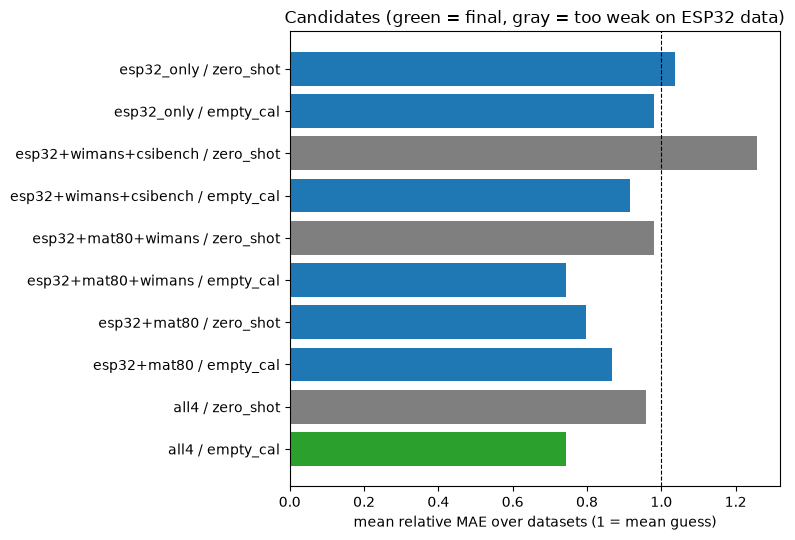

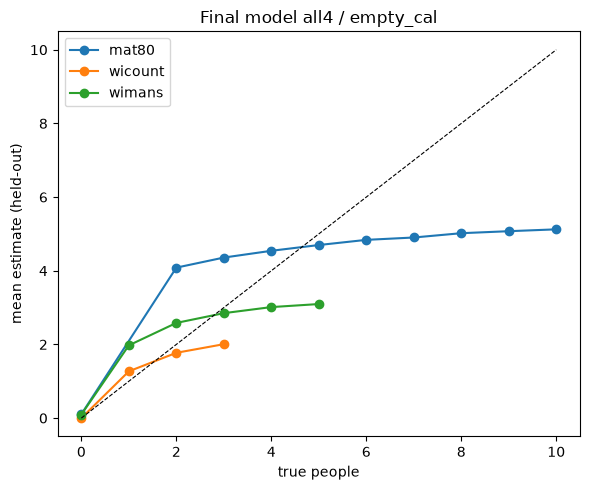

saved D:/wifi/results/phase4_final__mat80_wicount_wimans_csibench\PHASE4_RESULTS.md


In [14]:
# 12. Save results, figures and the Phase 4 report
results.to_csv(os.path.join(RESULTS, "results.csv"), index=False)
summary.reset_index().to_csv(os.path.join(RESULTS, "selection.csv"), index=False)
per_rec.to_csv(os.path.join(RESULTS, "recording_predictions.csv"), index=False)
clip_check.to_csv(os.path.join(RESULTS, "clip_check.csv"), index=False)
agree.to_csv(os.path.join(RESULTS, "clip_check_features.csv"))
replay.to_csv(os.path.join(RESULTS, "replay_wicount.csv"), index=False)
budget.to_csv(os.path.join(RESULTS, "esp32_budget.csv"), index=False)

fig_dir = os.path.join(RESULTS, "figures")
os.makedirs(fig_dir, exist_ok=True)

# ---- relative MAE per candidate (lower = better, 1 = no better than guessing the mean) ----
s = summary.reset_index()
s["label"] = s["experiment"] + " / " + s["mode"]
fig, ax = plt.subplots(figsize=(8, 0.45 * len(s) + 1))
colors = ["tab:green" if (e, m) == CHOSEN else ("tab:blue" if k else "tab:gray")
          for e, m, k in zip(s["experiment"], s["mode"], s["esp32_ok"])]
ax.barh(s["label"], s["rel_mae_mean"], color=colors)
ax.axvline(1.0, color="k", ls="--", lw=0.8)
ax.set_xlabel("mean relative MAE over datasets (1 = mean guess)")
ax.set_title("Candidates (green = final, gray = too weak on ESP32 data)")
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, "candidates_rel_mae.png"), dpi=120)
plt.show()

# ---- final model: mean estimate per true count, per dataset (shows saturation) ----
fin = preds[(preds["experiment"] == exp) & (preds["mode"] == mode)]
per_count = (fin.groupby(["dataset", "count"])
             .agg(n=("smoothed", "size"), mean_pred=("smoothed", "mean"),
                  exact=("smoothed", lambda p: float(np.mean(np.rint(p) == fin.loc[p.index, "count"]))))
             .reset_index())
fig, ax = plt.subplots(figsize=(6, 5))
for ds, h in per_count.groupby("dataset"):
    ax.plot(h["count"], h["mean_pred"], "o-", label=ds)
top = int(per_count["count"].max())
ax.plot([0, top], [0, top], "k--", lw=0.8)
ax.set_xlabel("true people")
ax.set_ylabel("mean estimate (held-out)")
ax.set_title(f"Final model {exp} / {mode}")
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, "final_mean_estimate_per_count.png"), dpi=120)
plt.show()
per_count.to_csv(os.path.join(RESULTS, "final_per_count.csv"), index=False)

# ---- markdown report ----
show = ["experiment", "mode", "test", "n", "mae", "rel_mae", "exact", "within1", "f1_4", "spearman_rec"]
lines = [
    "# Phase 4 results - final ESP32-S3 people counter (all labelled sources)", "",
    f"Generated {time.strftime('%Y-%m-%d %H:%M')}. One link, device preprocessing, "
    f"{ec.WIN_S} s windows every {ec.HOP_S} s, output = median of the last {ec.SMOOTH_S:.0f} s "
    "(WiMANS / CSI-Bench: one clip = one estimate).", "",
    "## Final model", "",
    f"- Chosen: **{exp} / {mode}**",
    f"- Rule: {card['selection']['rule']}",
    f"- Trained on: {', '.join(card['training_data'])} ({card['n_training_windows']} windows), "
    f"counts 0-{max_count}",
    f"- Calibration: {card['calibration_howto']}",
    f"- Size: {card['n_trees']} trees, {card['n_nodes']} nodes, ~{card['flash_bytes_est'] / 1024:.0f} KB flash",
    f"- Files: `{MODEL_DIR}/` (trees.json, counter_model.h, model.txt, model_card.json)", "",
    "## Selection (sites with an empty recording, smoothed MAE per dataset)", "",
    summary.reset_index().round(3).to_markdown(index=False), "",
    "## Held-out results of the final model (all sites)", "",
    held_out[show].round(3).to_markdown(index=False), "",
    "## Final model: mean estimate per true count", "",
    per_count.round(3).to_markdown(index=False), "",
    "## All candidates, all sites", "",
    table[show].round(3).to_markdown(index=False), "",
    "## Clip check (mat80 + WiCount windows; causal = what the ESP32 computes)", "",
    clip_check.round(3).to_markdown(index=False), "",
    "## Replay of the raw ESP32 CSVs through the saved bundle (pipeline check)", "",
    replay.to_markdown(index=False), "",
    "## ESP32-S3 budget (estimates)", "",
    budget.to_markdown(index=False), "",
    "## Caveats", "",
] + [f"- {c}" for c in card["caveats"]]

with open(os.path.join(RESULTS, "PHASE4_RESULTS.md"), "w") as f:
    f.write(chr(10).join(lines))
print("saved", os.path.join(RESULTS, "PHASE4_RESULTS.md"))

In [15]:
# 13. Done - how to use the model
print("Phase 4 finished.")
print("Model bundle :", MODEL_DIR)
print("Report       :", os.path.join(RESULTS, "PHASE4_RESULTS.md"))
print()
print("Python (demo / friend's app):")
print("    import esp32_counter as ec")
print("    model, card = ec.load_bundle(MODEL_DIR)")
print("    counter = ec.StreamingCounter(model)")
if card["calibration"] == "empty_cal":
    print("    counter.begin_calibration()        # room empty for the first 30 s")
print("    for t, amp52 in packets:             # amp52 = |CSI| of the 52 data tones")
print("        for r in counter.push(t, amp52):")
print("            if r['status'] == 'ok': print(r['count'])")
print()
print("ESP32 firmware: #include \"counter_model.h\" -> cc_prepare(raw_features, offset, x); cc_predict(x)")

Phase 4 finished.
Model bundle : D:/wifi/results/phase4_final__mat80_wicount_wimans_csibench/model_esp32_counter
Report       : D:/wifi/results/phase4_final__mat80_wicount_wimans_csibench\PHASE4_RESULTS.md

Python (demo / friend's app):
    import esp32_counter as ec
    model, card = ec.load_bundle(MODEL_DIR)
    counter = ec.StreamingCounter(model)
    counter.begin_calibration()        # room empty for the first 30 s
    for t, amp52 in packets:             # amp52 = |CSI| of the 52 data tones
        for r in counter.push(t, amp52):
            if r['status'] == 'ok': print(r['count'])

ESP32 firmware: #include "counter_model.h" -> cc_prepare(raw_features, offset, x); cc_predict(x)
